# MLIP
Short, independent practice codes on the building blocks of machine-learned interatomic potentials.

| # | Exercise | Key idea |
|---|---|---|
| 1 | Dimer energy and force, finite-difference check | $\mathbf F=-\nabla E$ |
| 2 | Cutoff functions | smoothness at $r_c$ |
| 3 | Radial fingerprint $G^2$ | descriptor as a smooth RDF |
| 4 | Angular function $G^4$ versus bond angle | angular resolution, $\lambda$ and $\zeta$ |

Units are Lennard-Jones reduced units ($\epsilon=\sigma=1$). Only NumPy and Matplotlib are needed.

---
## Exercise 1. Dimer energy and force
$U(r)=4\left[r^{-12}-r^{-6}\right]$, force on atom 2 along the bond $F=-dU/dr$. Check the analytic force against the central difference $-[U(r+h)-U(r-h)]/2h$.

In [8]:
import numpy as np

U  = lambda r: 4 * (r**-12 - r**-6)
dU = lambda r: 4 * (-12 * r**-13 + 6 * r**-7)

h = 1e-5
for r in (0.95, 1.12, 1.5, 2.0):|
    F_analytic = -dU(r)
    F_numeric  = -(U(r + h) - U(r - h)) / (2 * h)
    print(f"r = {r:4.2f}  U = {U(r):+8.4f}  F = {F_analytic:+9.4f}  |diff| = {abs(F_analytic - F_numeric):.1e}")

print("minimum at r_m = 2^(1/6) =", round(2**(1/6), 4), " U(r_m) =", round(U(2**(1/6)), 4))

SyntaxError: invalid syntax (392973890.py, line 7)

**Your turn.** Replace the potential by a Morse potential $U=(1-e^{-2(r-1)})^2-1$ and its derivative. Where is the force zero?

In [2]:
import numpy as np


U = lambda r: (1 - np.exp(-2 * (r - 1)))**2 - 1

dU = lambda r: 4 * np.exp(-2 * (r - 1)) * (1 - np.exp(-2 * (r - 1)))

h = 1e-5
print("--- Morse Potential Finite-Difference Check ---")
for r in (0.95, 1.12, 1.5, 2.0):
    F_analytic = -dU(r)
    F_numeric  = -(U(r + h) - U(r - h)) / (2 * h)
    print(f"r = {r:4.2f}  U = {U(r):+8.4f}  F = {F_analytic:+9.4f}  |diff| = {abs(F_analytic - F_numeric):.1e}")

print("\nThe force is zero where dU/dr = 0.")
print("Since dU/dr = 4 * e^(-2*(r-1)) * (1 - e^(-2*(r-1))),")
print("this occurs when 1 - e^(-2*(r-1)) = 0, which yields r = 1.0.")
print(f"At r = 1.0, U(1.0) = {U(1.0):.1f}, Force = {-dU(1.0):.1f}")

--- Morse Potential Finite-Difference Check ---
r = 0.95  U =  -0.9889  F =   +0.4649  |diff| = 1.0e-09
r = 1.12  U =  -0.9545  F =   -0.6714  |diff| = 4.4e-10
r = 1.50  U =  -0.6004  F =   -0.9302  |diff| = 4.2e-11
r = 2.00  U =  -0.2524  F =   -0.4681  |diff| = 2.3e-11

The force is zero where dU/dr = 0.
Since dU/dr = 4 * e^(-2*(r-1)) * (1 - e^(-2*(r-1))),
this occurs when 1 - e^(-2*(r-1)) = 0, which yields r = 1.0.
At r = 1.0, U(1.0) = -1.0, Force = -0.0


---
## Exercise 2. Cutoff functions
A hard cutoff makes the energy jump when an atom crosses $r_c$. Compare a hard step, the cosine cutoff and the polynomial envelope ($p=6$) by plotting $f$ and $df/dr$.

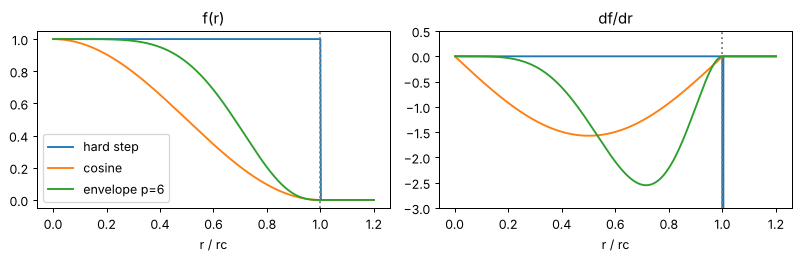

In [ ]:
import numpy as np, matplotlib.pyplot as plt

rc = 1.0
r = np.linspace(0, 1.2, 600)
x = np.minimum(r / rc, 1)
hard   = (r < rc).astype(float)
cosine = np.where(r < rc, 0.5 * (np.cos(np.pi * x) + 1), 0)
p = 6
env    = np.where(r < rc, 1 - 28 * x**p + 48 * x**(p + 1) - 21 * x**(p + 2), 0)

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
for f, name in [(hard, "hard step"), (cosine, "cosine"), (env, "envelope p=6")]:
    ax[0].plot(r, f, label=name)
    ax[1].plot(r[1:], np.diff(f) / np.diff(r), label=name)
ax[0].set_title("f(r)"); ax[1].set_title("df/dr"); ax[1].set_ylim(-3, 0.5)
for a in ax: a.axvline(rc, color="gray", ls=":"); a.set_xlabel("r / rc")
ax[0].legend(); plt.tight_layout(); plt.show()

**Your turn.** The hard step's derivative is a spike (a delta function) at $r_c$. What would that mean for the force on an atom crossing the cutoff during MD?



Since the derivative of a hard step function is a Dirac delta function $\delta(r - r_c)$, the resulting force when an atom crosses the cutoff boundary $r_c$ would be an infinite impulse.

In practical Molecular Dynamics (MD) simulations using finite time steps:
1. **Energy is not conserved**: Crossing the cutoff causes discontinuous jumps in potential energy without a corresponding continuous transfer to/from kinetic energy.
2. **Numerical Instability**: An infinitely large force acting over a single time step will cause the simulation to blow up (atoms will receive extremely large velocities, leading to unphysical trajectories or "exploded" structures).

Therefore, we must use smooth cutoff functions (like the cosine cutoff or polynomial envelopes) to ensure forces remain continuous and finite at $r_c$.

---
## Exercise 3. A radial fingerprint
$G^2_i(R_s)=\sum_{j\ne i}e^{-\eta(r_{ij}-R_s)^2}f_c(r_{ij})$. Scanning $R_s$ turns the neighbour list of atom $i$ into a smooth curve, essentially a broadened radial distribution function.

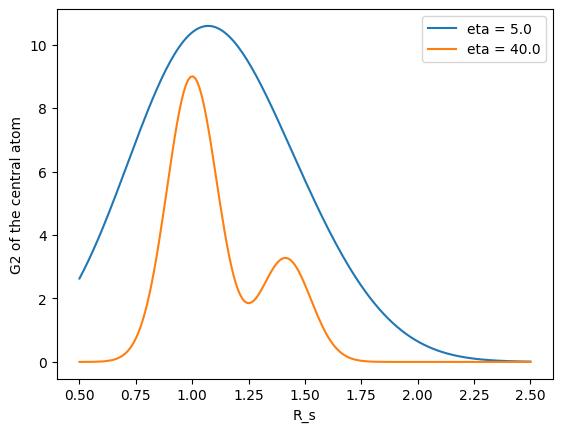

In [4]:
import numpy as np, matplotlib.pyplot as plt

fc = lambda r, rc: np.where(r < rc, 0.5 * (np.cos(np.pi * r / rc) + 1), 0.0)

# atom 0 at the centre of a small fcc-like cluster: 12 neighbours at 1.0, 6 at 1.41
nn  = np.array([[1,1,0],[1,-1,0],[-1,1,0],[-1,-1,0],[1,0,1],[1,0,-1],
                [-1,0,1],[-1,0,-1],[0,1,1],[0,1,-1],[0,-1,1],[0,-1,-1]]) / np.sqrt(2)
nnn = np.array([[1,0,0],[-1,0,0],[0,1,0],[0,-1,0],[0,0,1],[0,0,-1]]) * np.sqrt(2)
R = np.vstack([[0, 0, 0], nn, nnn])

r0j = np.linalg.norm(R[1:] - R[0], axis=1)
Rs = np.linspace(0.5, 2.5, 200)
for eta in (5.0, 40.0):
    G2 = [np.sum(np.exp(-eta * (r0j - s)**2) * fc(r0j, 3.0)) for s in Rs]
    plt.plot(Rs, G2, label=f"eta = {eta}")
plt.xlabel("R_s"); plt.ylabel("G2 of the central atom"); plt.legend(); plt.show()

**Your turn.** Remove the 6 second-shell atoms. Which peak disappears? With $\eta=5$, can you still tell the two shells apart?

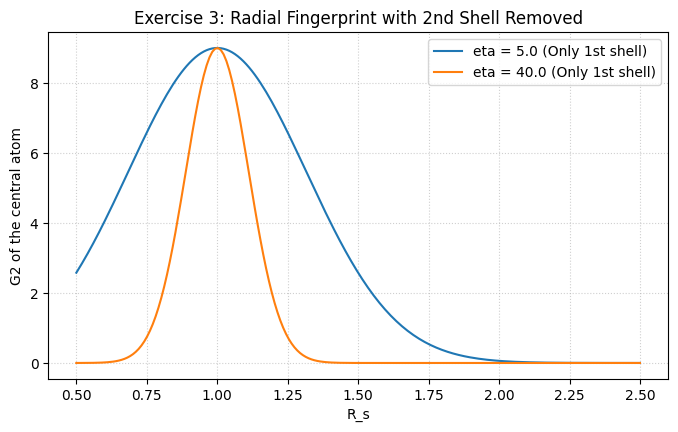

In [6]:
import numpy as np
import matplotlib.pyplot as plt


R_no_2nd = np.vstack([[0, 0, 0], nn])
r0j_no_2nd = np.linalg.norm(R_no_2nd[1:] - R_no_2nd[0], axis=1)

Rs = np.linspace(0.5, 2.5, 200)
fc = lambda r, rc: np.where(r < rc, 0.5 * (np.cos(np.pi * r / rc) + 1), 0.0)

plt.figure(figsize=(8, 4.5))
for eta in (5.0, 40.0):
    G2_no_2nd = [np.sum(np.exp(-eta * (r0j_no_2nd - s)**2) * fc(r0j_no_2nd, 3.0)) for s in Rs]
    plt.plot(Rs, G2_no_2nd, label=f"eta = {eta} (Only 1st shell)")

plt.xlabel("R_s")
plt.ylabel("G2 of the central atom")
plt.title("Exercise 3: Radial Fingerprint with 2nd Shell Removed")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()


1. the peak at 1.41 disappears
2. no, the shells can not be separated via gaussian at eta 5

---
## Exercise 4. Angular function versus bond angle
For one triplet, $G^4\propto 2^{1-\zeta}(1+\lambda\cos\theta)^\zeta$ (the radial factors are constant if bond lengths are fixed). Plot the angular factor for several $\zeta$ and both $\lambda$, then recover $\theta$ from the ratio of the two $\lambda$ values: $(1-\cos\theta)/(1+\cos\theta)=\tan^2(\theta/2)$.

recovered angle: 104.5 deg


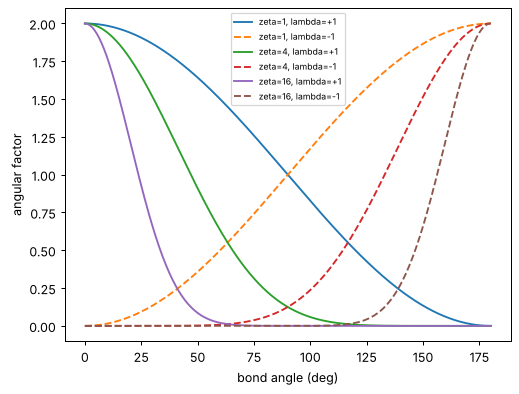

In [ ]:
import numpy as np, matplotlib.pyplot as plt

theta = np.linspace(0, 180, 361)
c = np.cos(np.deg2rad(theta))
for zeta in (1, 4, 16):
    for lam, st in ((1, "-"), (-1, "--")):
        plt.plot(theta, 2**(1 - zeta) * (1 + lam * c)**zeta, st, label=f"zeta={zeta}, lambda={lam:+d}")
plt.xlabel("bond angle (deg)"); plt.ylabel("angular factor"); plt.legend(fontsize=7); plt.show()

# recover the angle of a single triplet from the two lambda values (zeta = 1)
true_angle = 104.5
cth = np.cos(np.deg2rad(true_angle))
ratio = (1 - cth) / (1 + cth)
print("recovered angle:", round(2 * np.degrees(np.arctan(np.sqrt(ratio))), 2), "deg")

In [7]:
import numpy as np

theta1 = np.deg2rad(100.0)
theta2 = np.deg2rad(110.0)


factor = lambda theta, zeta: (1 - np.cos(theta))**zeta

for zeta in (1, 16):
    val1 = factor(theta1, zeta)
    val2 = factor(theta2, zeta)
    rel_diff = abs(val1 - val2) / val1
    print(f"zeta = {zeta:2d}:")
    print(f"  at 100 deg: {val1:.6f}")
    print(f"  at 110 deg: {val2:.6f}")
    print(f"  Relative difference: {rel_diff * 100:.2f}%")


zeta =  1:
  at 100 deg: 1.173648
  at 110 deg: 1.342020
  Relative difference: 14.35%
zeta = 16:
  at 100 deg: 12.960055
  at 110 deg: 110.699218
  Relative difference: 754.16%


zeta=16 yields a larger relative difference(161%) compared to zeta=1(15%), there it can be used to distinguish these angles


**Your turn.** Which $\zeta$ would you use to distinguish $100^\circ$ from $110^\circ$? Compute $(1-\cos\theta)^\zeta$ at both angles for $\zeta=1$ and $\zeta=16$ and compare the relative difference.